## Imported important libraries

In [41]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, confusion_matrix, classification_report,ConfusionMatrixDisplay)
import pickle
import shap

## Load the Dataset

In [2]:
df = pd.read_csv('susceptibility_training_table.csv')

# See the first 5 rows

In [3]:
df.head(5)

,point_id,station_id,basin,lat,lon,elevation_m,slope_deg,dist_to_river_m,drainage_density_km_per_km2,landcover_class,label
0,SW90_0_0,SW90,brahmaputra,25.0997,89.5695,17.955149,0.611079,1010.434527,0.638643,40,0
1,SW90_0_1,SW90,brahmaputra,25.0997,89.5995,12.219988,4.605155,370.825399,0.814095,60,0
2,SW90_0_2,SW90,brahmaputra,25.0997,89.6295,17.696609,0.281487,263.586822,1.143943,30,0
3,SW90_0_3,SW90,brahmaputra,25.0997,89.6595,11.500000,0.000000,1445.847475,1.277286,80,0
4,SW90_0_4,SW90,brahmaputra,25.0997,89.6895,11.500000,0.000000,184.182700,1.228160,80,0


## See the Last 5 rows

In [4]:
df.tail(5)

,point_id,station_id,basin,lat,lon,elevation_m,slope_deg,dist_to_river_m,drainage_density_km_per_km2,landcover_class,label
1376,CO05_6_2,CO05,cht,21.5172,91.9758,5.616333,1.812375,632.809182,0.866229,95,0
1377,CO05_6_3,CO05,cht,21.5172,92.0058,0.000000,1.110126,1159.780050,0.664109,95,1
1378,CO05_6_4,CO05,cht,21.5172,92.0358,1.463102,0.226349,146.271124,1.335436,80,1
1379,CO05_6_5,CO05,cht,21.5172,92.0658,14.221318,6.446821,632.804099,1.097223,10,0
1380,CO05_6_6,CO05,cht,21.5172,92.0958,21.810600,8.129897,171.579168,1.775769,10,0


## Check The columns

In [5]:
df.columns

Index(['point_id', 'station_id', 'basin', 'lat', 'lon', 'elevation_m',
       'slope_deg', 'dist_to_river_m', 'drainage_density_km_per_km2',
       'landcover_class', 'label'],
      dtype='str')

## Dataset Shape

In [6]:
df.shape

(1381, 11)

There are almost 1381 rowns and 11 columns present in this dataset

## Dataset Information

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1381 entries, 0 to 1380
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   point_id                     1381 non-null   str    
 1   station_id                   1381 non-null   str    
 2   basin                        1381 non-null   str    
 3   lat                          1381 non-null   float64
 4   lon                          1381 non-null   float64
 5   elevation_m                  1381 non-null   float64
 6   slope_deg                    1381 non-null   float64
 7   dist_to_river_m              1381 non-null   float64
 8   drainage_density_km_per_km2  1381 non-null   float64
 9   landcover_class              1381 non-null   int64  
 10  label                        1381 non-null   int64  
dtypes: float64(6), int64(2), str(3)
memory usage: 144.6 KB


## Statistical Analysis

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
lat,1381.0,23.971219,1.183226,21.337200,22.875600,23.960000,24.925200,26.006700
lon,1381.0,90.475280,0.995364,88.939400,89.640900,90.299600,91.365000,92.308300
elevation_m,1381.0,17.587058,28.967232,-0.629735,4.463551,10.018256,18.898256,416.116669
slope_deg,1381.0,2.878753,4.460336,0.000000,0.289015,1.127268,3.813164,36.497028
dist_to_river_m,1381.0,723.299586,543.353662,0.001972,294.913080,618.622893,1052.860920,3131.194007
drainage_density_km_per_km2,1381.0,0.993578,0.406206,0.000000,0.715842,0.961474,1.256032,3.775313
landcover_class,1381.0,34.779146,22.749544,10.000000,10.000000,40.000000,40.000000,95.000000
label,1381.0,0.262129,0.439952,0.000000,0.000000,0.000000,1.000000,1.000000


## EDA

In [9]:
df.isna().sum()

point_id                       0
station_id                     0
basin                          0
lat                            0
lon                            0
elevation_m                    0
slope_deg                      0
dist_to_river_m                0
drainage_density_km_per_km2    0
landcover_class                0
label                          0
dtype: int64

There is no nan values present in this dataset

In [10]:
df.duplicated().sum()

np.int64(0)

There is no duplicated values present in this dataset

# Dataset Visualization

## Target Class Distribution

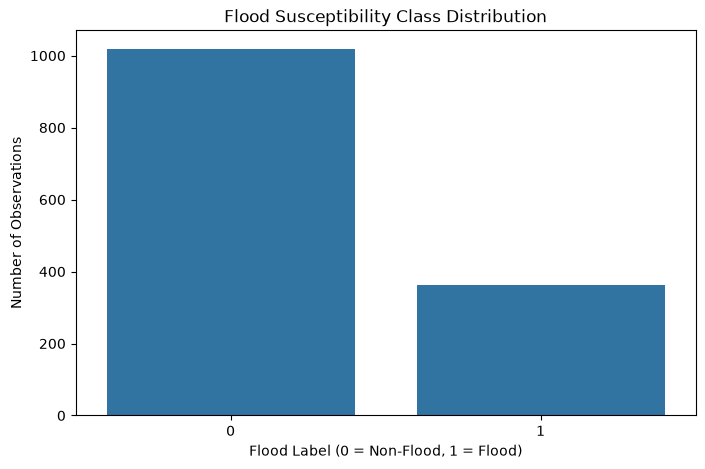

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="label")

plt.title("Flood Susceptibility Class Distribution")
plt.xlabel("Flood Label (0 = Non-Flood, 1 = Flood)")
plt.ylabel("Number of Observations")

plt.show()

## Correlation Heatmap

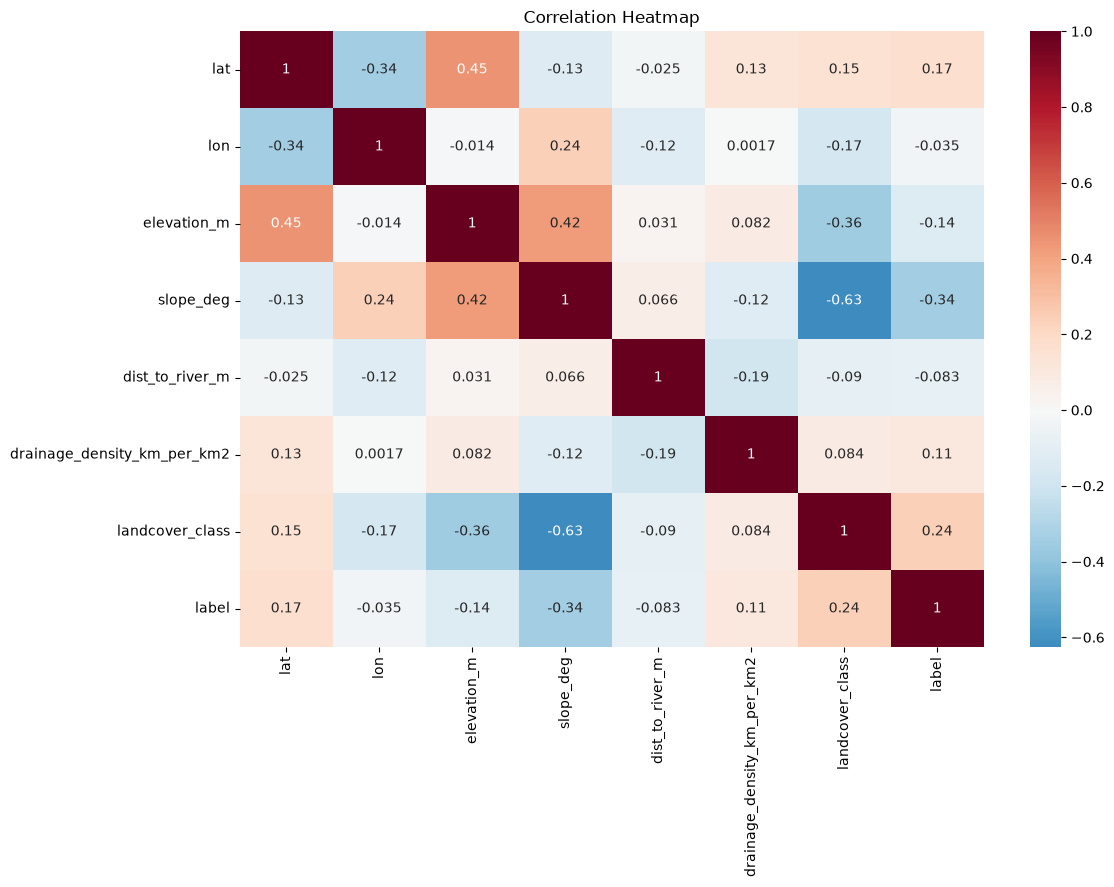

In [12]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.select_dtypes(include="number").corr(method="spearman"),annot=True, cmap="RdBu_r", center=0)
plt.title("Correlation Heatmap")
plt.show()

## Numerical Feature Distributions

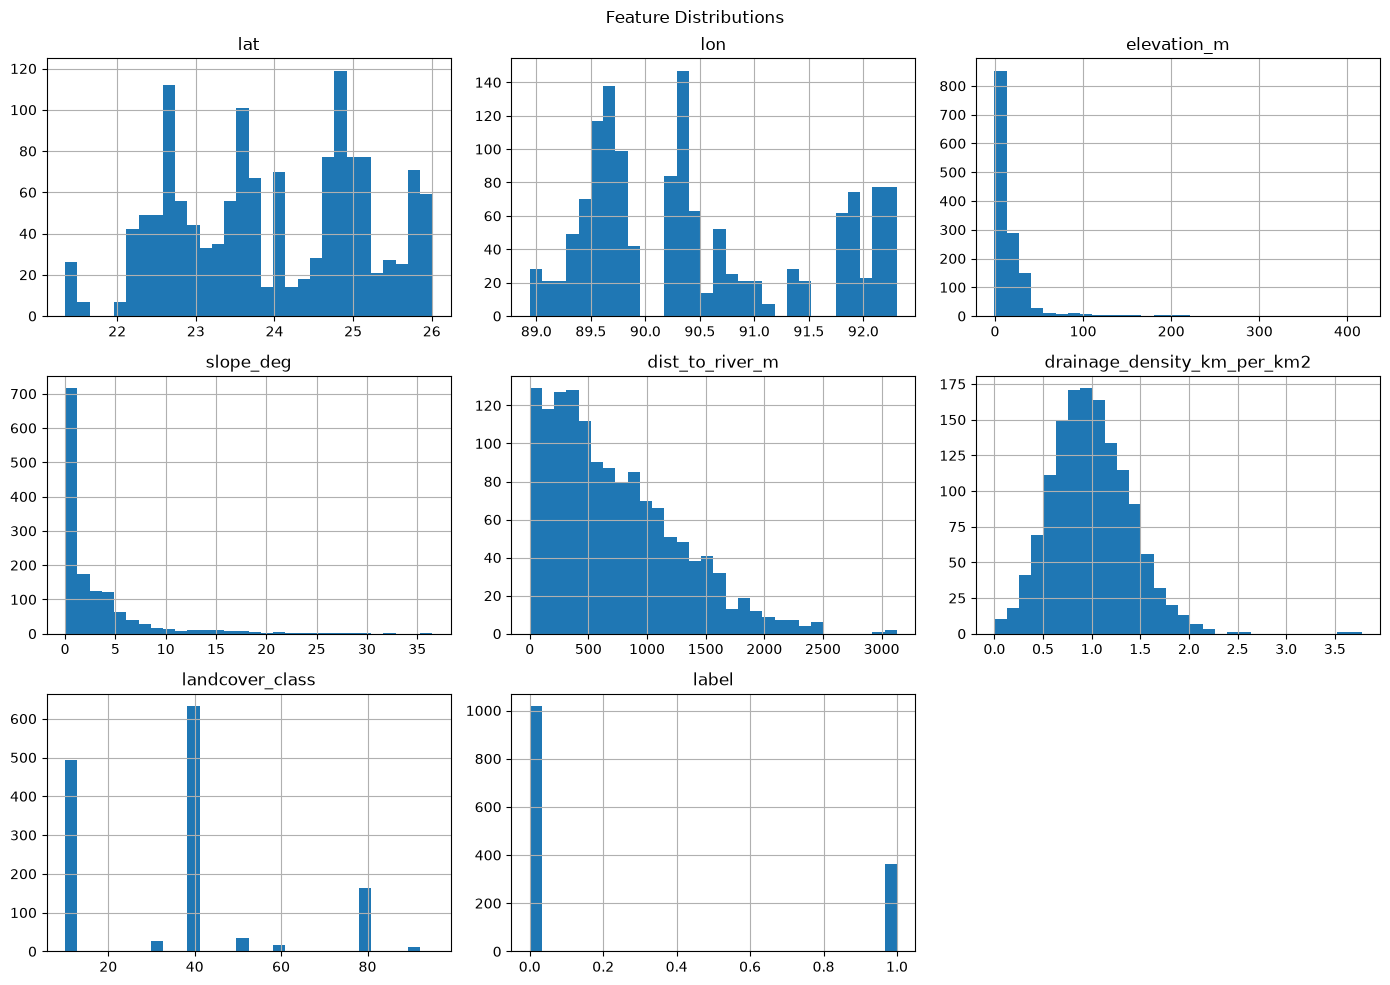

In [13]:
df.select_dtypes(include="number").hist(figsize=(14, 10), bins=30)
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

## Elevation vs Flood Label

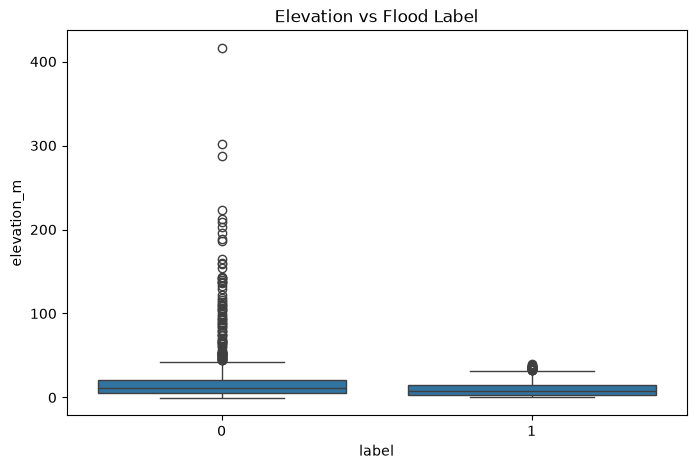

In [14]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="label", y="elevation_m")
plt.title("Elevation vs Flood Label")
plt.show()

## Distance to River vs Flood Label

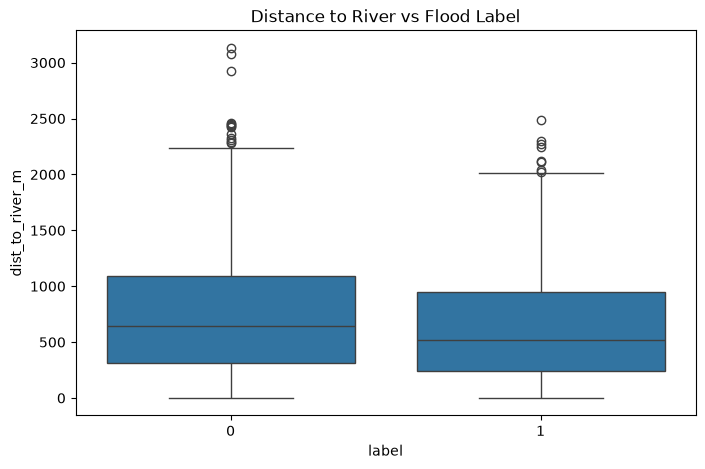

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="label", y="dist_to_river_m")
plt.title("Distance to River vs Flood Label")
plt.show()

## Geographic Flood Distribution

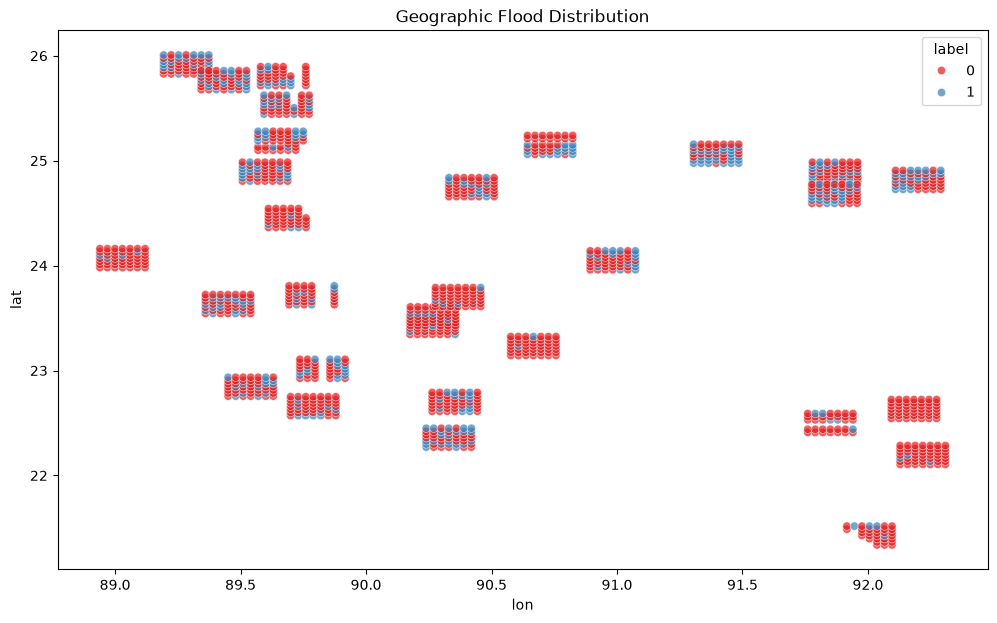

In [16]:
plt.figure(figsize=(12, 7))
sns.scatterplot(data=df, x="lon", y="lat", hue="label", palette="Set1", alpha=0.7)
plt.title("Geographic Flood Distribution")
plt.show()

## Flood Susceptibility by Basin

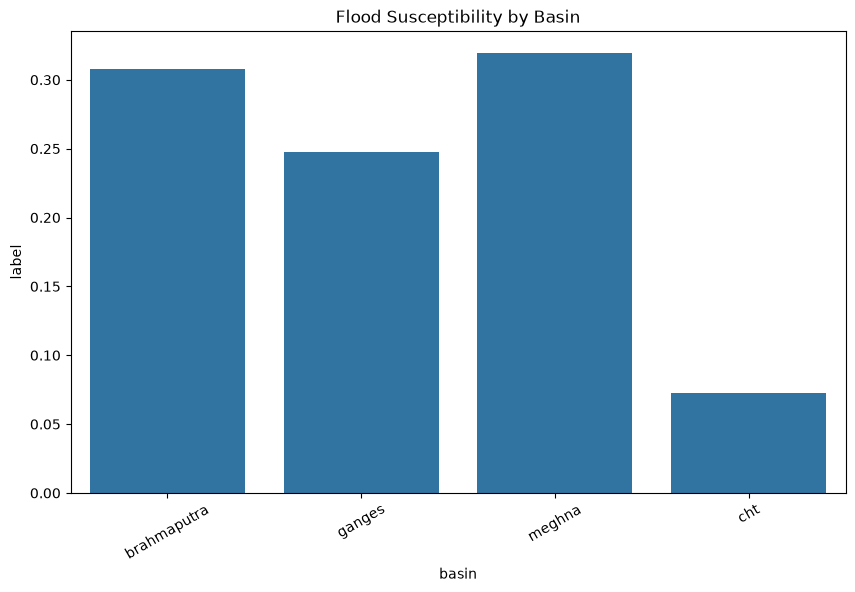

In [17]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x="basin", y="label", errorbar=None)
plt.title("Flood Susceptibility by Basin")
plt.xticks(rotation=30)
plt.show()

## Land Cover vs Flood Susceptibility

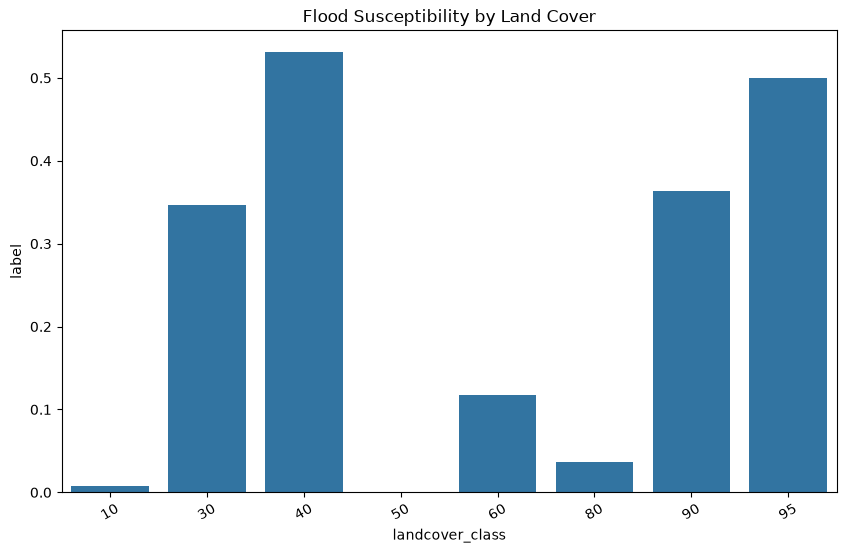

In [18]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x="landcover_class", y="label", errorbar=None)
plt.title("Flood Susceptibility by Land Cover")
plt.xticks(rotation=30)
plt.show()

## Performing Encoding and Scalling at the same time on a single cell


In [19]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

for col in df.select_dtypes(include=["object", "category"]).columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

for col in df.select_dtypes(include="number").columns:
    if col not in ["point_id", "label"]:
        df[col] = StandardScaler().fit_transform(df[[col]])

df.head()

C:\Users\Fahim Abrar\AppData\Local\Temp\ipykernel_11416\3388888202.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=["object", "category"]).columns:


,point_id,station_id,basin,lat,lon,elevation_m,slope_deg,dist_to_river_m,drainage_density_km_per_km2,landcover_class,label
0,1153,1.199286,-1.428121,0.954077,-0.910328,0.012712,-0.508593,0.528641,-0.874096,0.229576,0
1,1154,1.199286,-1.428121,0.954077,-0.880177,-0.185348,0.387197,-0.648936,-0.442013,1.109033,0
2,1155,1.199286,-1.428121,0.954077,-0.850027,0.003783,-0.582514,-0.846372,0.370303,-0.210153,0
3,1156,1.199286,-1.428121,0.954077,-0.819876,-0.210212,-0.645646,1.330275,0.698687,1.988490,0
4,1157,1.199286,-1.428121,0.954077,-0.789725,-0.210212,-0.645646,-0.992562,0.577703,1.988490,0


## Data Spliting

In [21]:
x = df.drop('label', axis=1)
y=df['label']

## Train Test Split apply

In [31]:
X_train , X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

## Performing Logistic Regression

Best Parameters: {'solver': 'liblinear', 'class_weight': 'balanced', 'C': 10}
Accuracy: 0.6967509025270758
Precision: 0.4626865671641791
Recall: 0.8378378378378378
F1 Score: 0.5961538461538461

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.65      0.76       203
           1       0.46      0.84      0.60        74

    accuracy                           0.70       277
   macro avg       0.69      0.74      0.68       277
weighted avg       0.79      0.70      0.71       277



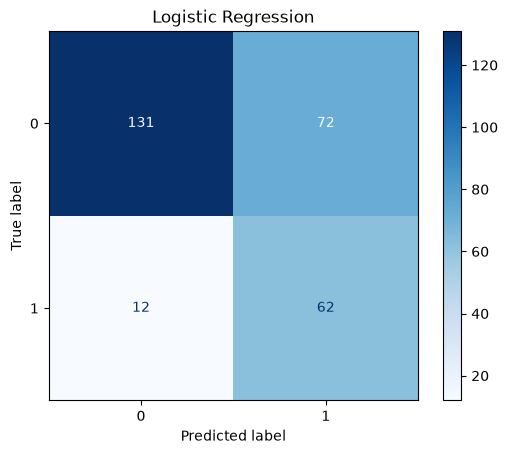

In [32]:
search = RandomizedSearchCV(
    LogisticRegression(max_iter=2000),
    {
        "C": [0.01, 0.1, 1, 10, 100],
        "solver": ["lbfgs", "liblinear"],
        "class_weight": [None, "balanced"]
    },
    n_iter=10, cv=5, scoring="f1",
    n_jobs=-1, random_state=42
)

search.fit(X_train, y_train)

y_pred = search.best_estimator_.predict(X_test)

print("Best Parameters:", search.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Logistic Regression")
plt.show()

## Performing Decision Tree CLassifier

Best Parameters: {'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': 5, 'criterion': 'entropy', 'class_weight': None}
Accuracy: 0.8231046931407943
Precision: 0.6288659793814433
Recall: 0.8243243243243243
F1 Score: 0.7134502923976608

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.82      0.87       203
           1       0.63      0.82      0.71        74

    accuracy                           0.82       277
   macro avg       0.78      0.82      0.79       277
weighted avg       0.85      0.82      0.83       277



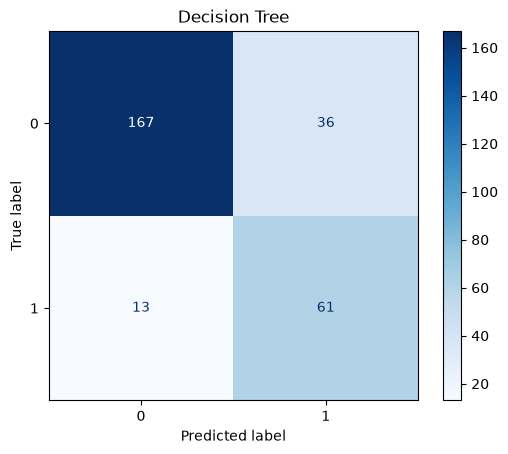

In [33]:
search = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=42),
    {
        "criterion": ["gini", "entropy", "log_loss"],
        "max_depth": [3, 5, 10, 15, 20, None],
        "min_samples_split": [2, 5, 10, 20],
        "min_samples_leaf": [1, 2, 5, 10],
        "class_weight": [None, "balanced"]
    },
    n_iter=20, cv=5, scoring="f1",
    n_jobs=-1, random_state=42
)

search.fit(X_train, y_train)

y_pred = search.best_estimator_.predict(X_test)

print("Best Parameters:", search.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Decision Tree")
plt.show()

## Performing Random Forest 

Best Parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 20, 'class_weight': 'balanced'}
Accuracy: 0.8447653429602888
Precision: 0.6703296703296703
Recall: 0.8243243243243243
F1 Score: 0.7393939393939394

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.85      0.89       203
           1       0.67      0.82      0.74        74

    accuracy                           0.84       277
   macro avg       0.80      0.84      0.81       277
weighted avg       0.86      0.84      0.85       277



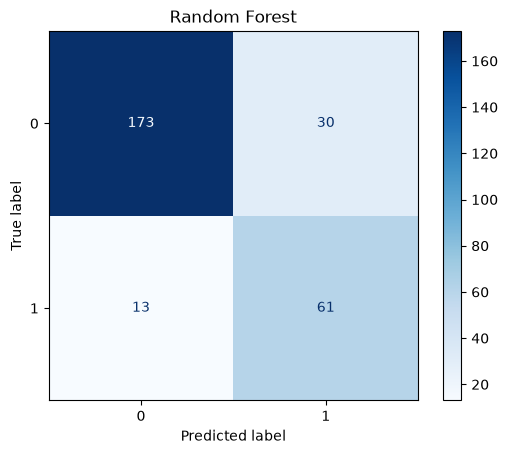

In [34]:
search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    {
        "n_estimators": [100, 200, 300, 500],
        "max_depth": [5, 10, 15, 20, None],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", "log2"],
        "class_weight": [None, "balanced", "balanced_subsample"]
    },
    n_iter=20, cv=5, scoring="f1",
    n_jobs=-1, random_state=42
)

search.fit(X_train, y_train)

y_pred = search.best_estimator_.predict(X_test)

print("Best Parameters:", search.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Random Forest")
plt.show()

## Performing CatBoost Classifier

Best Parameters: {'learning_rate': 0.03, 'l2_leaf_reg': 5, 'iterations': 300, 'depth': 4}
Accuracy: 0.8411552346570397
Precision: 0.7083333333333334
Recall: 0.6891891891891891
F1 Score: 0.6986301369863014

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.90      0.89       203
           1       0.71      0.69      0.70        74

    accuracy                           0.84       277
   macro avg       0.80      0.79      0.80       277
weighted avg       0.84      0.84      0.84       277



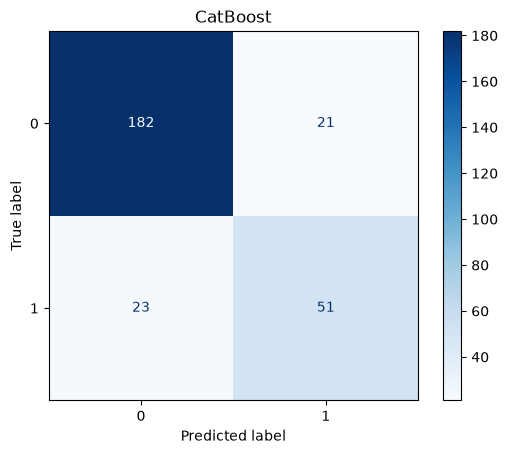

In [ ]:
search = RandomizedSearchCV(
    CatBoostClassifier(
        verbose=0,
        random_seed=42,
        allow_writing_files=False
    ),
    {
        "iterations": [300, 500, 700, 1000],
        "depth": [4, 5, 6, 7, 8],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "l2_leaf_reg": [1, 3, 5, 7, 9]
    },
    n_iter=15, cv=5, scoring="f1",
    n_jobs=-1, random_state=42
)

search.fit(X_train, y_train)

y_pred = search.best_estimator_.predict(X_test)

print("Best Parameters:", search.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("CatBoost")

plt.show()

## Performing LGBM Classifier

Best Parameters: {'reg_lambda': 5, 'num_leaves': 50, 'n_estimators': 100, 'min_child_samples': 50, 'max_depth': 5, 'learning_rate': 0.03}
Accuracy: 0.8375451263537906
Precision: 0.6986301369863014
Recall: 0.6891891891891891
F1 Score: 0.6938775510204082

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.89      0.89       203
           1       0.70      0.69      0.69        74

    accuracy                           0.84       277
   macro avg       0.79      0.79      0.79       277
weighted avg       0.84      0.84      0.84       277



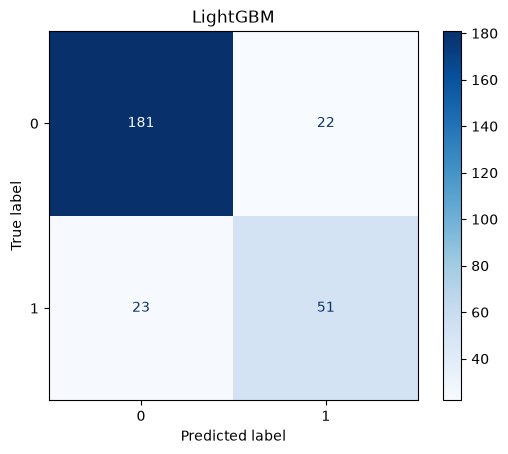

In [36]:
search = RandomizedSearchCV(
    LGBMClassifier(random_state=42, verbosity=-1),
    {
        "n_estimators": [100, 200, 300, 500],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "max_depth": [-1, 5, 10, 15],
        "num_leaves": [15, 31, 50, 70],
        "min_child_samples": [10, 20, 30, 50],
        "reg_lambda": [0, 1, 5, 10]
    },
    n_iter=15, cv=5, scoring="f1",
    n_jobs=-1, random_state=42
)

search.fit(X_train, y_train)

y_pred = search.best_estimator_.predict(X_test)

print("Best Parameters:", search.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("LightGBM")
plt.show()

In [40]:
import pickle

with open("prohori_flood_model.pkl", "wb") as file:
    pickle.dump(search.best_estimator_, file)

print("Model saved successfully!")

Model saved successfully!


In [44]:
with open("prohori_flood_model.pkl", "rb") as file:
    model = pickle.load(file)
    

In [ ]:
explainer = shap.Explainer(model, X_train)

shap_values = explainer(X_test)

Background dataset has 1104 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1104 when initializing the masker.


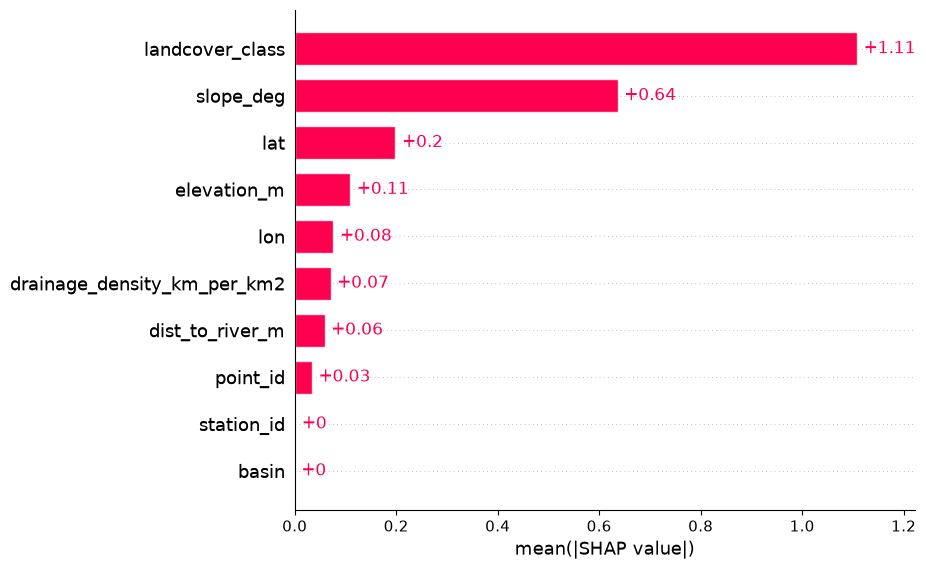

In [46]:
shap.plots.bar(shap_values, max_display=10)

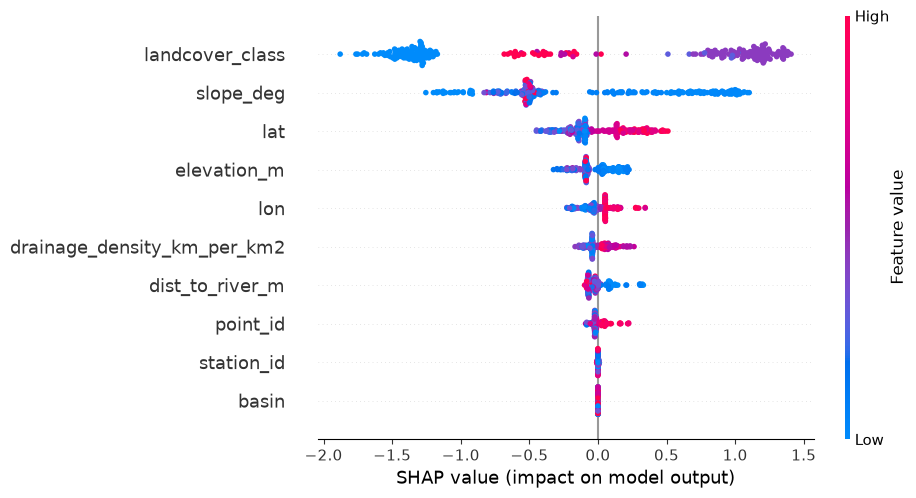

In [47]:
shap.plots.beeswarm(shap_values, max_display=10)

## PROHORI Flood Risk Classification Engine

In [ ]:
with open("prohori_flood_model.pkl", "rb") as file:
    prohori_model = pickle.load(file)

print("PROHORI model loaded successfully!")

PROHORI model loaded successfully!


In [52]:
prohori_risk_probability = prohori_model.predict_proba(X_test)[:, 1]

print(prohori_risk_probability[:10])

[0.03122745 0.02676712 0.65071585 0.8018907  0.02676712 0.02676712
 0.59017248 0.63305115 0.32182976 0.27333571]
